# Lung Cancer Risk From Tabular Features (survey data)

Real CT imaging datasets (LIDC-IDRI, NLST) are huge and gated, and processing CTs needs a serious GPU plus a couple of days of DICOM-wrangling I don't have time for. So I'm working with a small real tabular dataset instead: the "survey lung cancer" data (309 respondents; Kaggle `nancyalaswad90/lung-cancer`, loaded from the Hugging Face copy `nateraw/lung-cancer`). It has gender, age, smoking, yellow fingers, anxiety, peer pressure, chronic disease, fatigue, allergy, wheezing, alcohol, coughing, shortness of breath, swallowing difficulty and chest pain, plus a lung cancer yes/no label.

**This is a learning project, not a clinical screening tool.** The dataset card says the data comes from an online lung cancer prediction system, so these are self-reported answers with no documented clinical verification of the label. It's also tiny and very imbalanced (most respondents are labeled YES), so I treat the results as a pipeline exercise on real but weak data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

## Load the survey data

In the raw file the yes/no answers are coded 1 = no, 2 = yes. I recode them to 0/1. A number of rows are exact duplicates, which I drop so the same respondent can't land in both train and test.

In [2]:
CSV = Path("../../data/lung_cancer/survey_lung_cancer.csv")
if not CSV.exists():
    CSV.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://huggingface.co/datasets/nateraw/lung-cancer/resolve/main/survey%20lung%20cancer.csv", CSV)
raw = pd.read_csv(CSV)
raw.columns = [c.strip().lower().replace(" ", "_") for c in raw.columns]
print("raw shape:", raw.shape, " duplicate rows:", raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)

yes_no = [c for c in df.columns if c not in ("gender", "age", "lung_cancer")]
df[yes_no] = df[yes_no] - 1                      # 1/2 -> 0/1
df["male"] = (df["gender"] == "M").astype(int)
df["cancer"] = (df["lung_cancer"] == "YES").astype(int)
df = df.drop(columns=["gender", "lung_cancer"])
print("after dedup:", df.shape, "  positive rate:", df.cancer.mean().round(3))
df.head()

raw shape: (309, 16)  duplicate rows: 33
after dedup: (276, 16)   positive rate: 0.862


,age,smoking,yellow_fingers,anxiety,peer_pressure,chronic_disease,fatigue,allergy,wheezing,alcohol_consuming,coughing,shortness_of_breath,swallowing_difficulty,chest_pain,male,cancer
0,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1,1
1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1,1
2,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0,0
3,63,1,1,1,0,0,0,0,0,1,0,0,1,1,1,0
4,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0,0


## Quick EDA

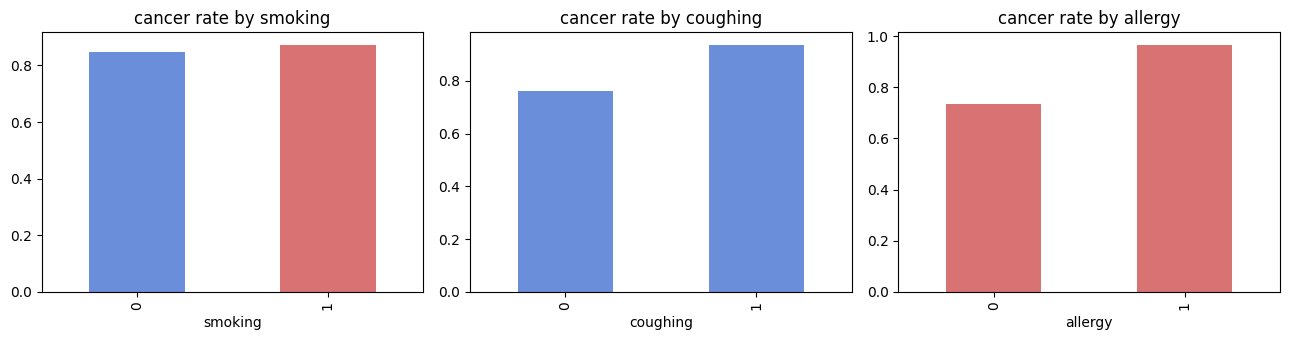

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("smoking")["cancer"].mean().plot(kind="bar", ax=axes[0], color=["#6b8edb", "#d97373"])
axes[0].set_title("cancer rate by smoking")
df.groupby("coughing")["cancer"].mean().plot(kind="bar", ax=axes[1], color="#6b8edb")
axes[1].set_title("cancer rate by coughing")
df.groupby("allergy")["cancer"].mean().plot(kind="bar", ax=axes[2], color="#d97373")
axes[2].set_title("cancer rate by allergy")
plt.tight_layout(); plt.show()

## Random forest and logistic regression with stratified CV

In [4]:
features = [c for c in df.columns if c != "cancer"]
X = df[features].values
y = df["cancer"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=11)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)

rf = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=11, n_jobs=2)
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
for name, m in [("RandomForest", rf), ("LogReg", lr)]:
    auc_cv = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:12s} 5-fold CV AUC on train: mean={auc_cv.mean():.3f}  std={auc_cv.std():.3f}")

rf.fit(X_train, y_train)
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"\nrandom forest test AUC: {roc_auc_score(y_test, proba):.3f}  (test rows: {len(y_test)}, negatives: {(y_test == 0).sum()})")
print(classification_report(y_test, pred, target_names=["no", "yes"], digits=3))

imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("feature importance (top 8):")
print(imp.head(8).round(3).to_string())

RandomForest 5-fold CV AUC on train: mean=0.904  std=0.024
LogReg       5-fold CV AUC on train: mean=0.917  std=0.017



random forest test AUC: 0.980  (test rows: 69, negatives: 9)
              precision    recall  f1-score   support

          no      0.875     0.778     0.824         9
         yes      0.967     0.983     0.975        60

    accuracy                          0.957        69
   macro avg      0.921     0.881     0.899        69
weighted avg      0.955     0.957     0.955        69

feature importance (top 8):
age                      0.133
allergy                  0.132
swallowing_difficulty    0.108
alcohol_consuming        0.098
peer_pressure            0.067
chronic_disease          0.064
fatigue                  0.057
yellow_fingers           0.056


## Honesty section

Numbers first. After dropping 33 duplicate rows there are 276 respondents, 86% of them labeled YES. Five-fold CV AUC on the training part is 0.904 for the random forest and 0.917 for logistic regression. The test AUC of 0.980 looks great but it rests on only 9 negative rows, so I trust the CV numbers far more.

The EDA is the more interesting part, and it's a warning. Smoking barely moves the label in this data (84.9% YES for non-smokers vs 87.3% for smokers), while allergy (73.6% vs 96.7%), alcohol and coughing separate the classes much more. The forest's top features are age, allergy, swallowing difficulty and alcohol. That's not what the epidemiology says, which tells me more about how this survey was collected than about lung cancer. It's a reminder that a "real" dataset can still be a poor stand-in for the clinical question.

Real lung-cancer screening uses LDCT (low-dose CT) combined with risk models like Tammemägi PLCOm2012, and the screening guidelines (USPSTF) are written in pack-years and age cutoffs for good reason. None of that came from this notebook. This is a "I can build and sanity-check the tabular pipeline" exercise.

If I had real data and a real budget: 3D CNN on LDCT volumes with proper nodule annotations, validated against a held-out hospital.